<a href="https://www.kaggle.com/code/lalit7881/disney-world-crowd-wait-time-analysis-70?scriptVersionId=364791302" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/ll_classification.csv
/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/chained_index.csv
/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/coverage_by_year.csv
/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/calendar_enriched.csv
/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/ll_split_index.csv
/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/park_stats.csv
/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/ride_stats.csv


## Loading dataset

In [2]:
cal = pd.read_csv('/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/calendar_enriched.csv')
chained = pd.read_csv('/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/chained_index.csv')
coverage = pd.read_csv('/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/coverage_by_year.csv')
ll_class = pd.read_csv('/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/ll_classification.csv')
park_stats = pd.read_csv('/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/park_stats.csv')
ride_stats = pd.read_csv('/kaggle/input/datasets/chadwambles/walt-disney-world-wait-times/ride_stats.csv')

In [3]:
print(cal.head())

   park_id park_name        date  year  month month_name day_of_week  \
0        5     Epcot  2015-01-01  2015      1        Jan    Thursday   
1        5     Epcot  2015-01-02  2015      1        Jan      Friday   
2        5     Epcot  2015-01-03  2015      1        Jan    Saturday   
3        5     Epcot  2015-01-04  2015      1        Jan      Sunday   
4        5     Epcot  2015-01-05  2015      1        Jan      Monday   

   dow_number  is_weekend  crowd_level_pct  crowd_rel_to_year  \
0           4           0               73              1.344   
1           5           0               74              1.363   
2           6           1               58              1.068   
3           7           1               14              0.258   
4           1           0               15              0.276   

   operating_minutes  has_early_entry  has_extended_evening  \
0              780.0                0                     0   
1              780.0                0             

In [4]:
cal.tail()

,park_id,park_name,date,year,month,month_name,day_of_week,dow_number,is_weekend,crowd_level_pct,crowd_rel_to_year,operating_minutes,has_early_entry,has_extended_evening,has_special_event,is_holiday,is_rainy
16677,8,Animal Kingdom,2026-09-26,2026,9,Sep,Saturday,6,1,19,0.492,720.0,1,0,0,0,0
16678,8,Animal Kingdom,2026-09-27,2026,9,Sep,Sunday,7,1,17,0.440,600.0,1,0,0,0,0
16679,8,Animal Kingdom,2026-09-28,2026,9,Sep,Monday,1,0,20,0.518,600.0,1,0,0,0,0
16680,8,Animal Kingdom,2026-09-29,2026,9,Sep,Tuesday,2,0,16,0.414,600.0,1,0,0,0,0
16681,8,Animal Kingdom,2026-09-30,2026,9,Sep,Wednesday,3,0,13,0.336,600.0,1,0,0,0,0


In [5]:
cal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16682 entries, 0 to 16681
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   park_id               16682 non-null  int64  
 1   park_name             16682 non-null  object 
 2   date                  16682 non-null  object 
 3   year                  16682 non-null  int64  
 4   month                 16682 non-null  int64  
 5   month_name            16682 non-null  object 
 6   day_of_week           16682 non-null  object 
 7   dow_number            16682 non-null  int64  
 8   is_weekend            16682 non-null  int64  
 9   crowd_level_pct       16682 non-null  int64  
 10  crowd_rel_to_year     16682 non-null  float64
 11  operating_minutes     16052 non-null  float64
 12  has_early_entry       16682 non-null  int64  
 13  has_extended_evening  16682 non-null  int64  
 14  has_special_event     16682 non-null  int64  
 15  is_holiday         

In [6]:
cal.describe()

,park_id,year,month,dow_number,is_weekend,crowd_level_pct,crowd_rel_to_year,operating_minutes,has_early_entry,has_extended_evening,has_special_event,is_holiday,is_rainy
count,16682.000000,16682.000000,16682.000000,16682.000000,16682.000000,16682.000000,16682.000000,16052.000000,16682.000000,16682.000000,16682.000000,16682.000000,16682.000000
mean,6.500420,2020.391560,6.468409,4.001259,0.286057,52.765076,0.999994,721.400698,0.415178,0.029793,0.034468,0.032130,0.217120
std,1.118014,3.440122,3.453024,2.000404,0.451930,27.736045,0.512644,93.429656,0.492767,0.170020,0.182434,0.176352,0.412298
min,5.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,240.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,2017.000000,3.000000,2.000000,0.000000,30.000000,0.618000,660.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,7.000000,2021.000000,7.000000,4.000000,0.000000,54.000000,1.015000,720.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8.000000,2023.000000,9.000000,6.000000,1.000000,77.000000,1.348000,780.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,8.000000,2026.000000,12.000000,7.000000,1.000000,100.000000,3.148000,1440.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
cal.isnull().sum()

park_id                   0
park_name                 0
date                      0
year                      0
month                     0
month_name                0
day_of_week               0
dow_number                0
is_weekend                0
crowd_level_pct           0
crowd_rel_to_year         0
operating_minutes       630
has_early_entry           0
has_extended_evening      0
has_special_event         0
is_holiday                0
is_rainy                  0
dtype: int64

In [8]:
cal.duplicated().sum()

np.int64(0)

In [9]:
cal.dtypes

park_id                   int64
park_name                object
date                     object
year                      int64
month                     int64
month_name               object
day_of_week              object
dow_number                int64
is_weekend                int64
crowd_level_pct           int64
crowd_rel_to_year       float64
operating_minutes       float64
has_early_entry           int64
has_extended_evening      int64
has_special_event         int64
is_holiday                int64
is_rainy                  int64
dtype: object

In [10]:
cal.shape

(16682, 17)

In [11]:
cal.columns

Index(['park_id', 'park_name', 'date', 'year', 'month', 'month_name',
       'day_of_week', 'dow_number', 'is_weekend', 'crowd_level_pct',
       'crowd_rel_to_year', 'operating_minutes', 'has_early_entry',
       'has_extended_evening', 'has_special_event', 'is_holiday', 'is_rainy'],
      dtype='object')

In [12]:
cal.nunique()

park_id                    4
park_name                  4
date                    4173
year                      12
month                     12
month_name                12
day_of_week                7
dow_number                 7
is_weekend                 2
crowd_level_pct          101
crowd_rel_to_year       1851
operating_minutes         26
has_early_entry            2
has_extended_evening       2
has_special_event          2
is_holiday                 2
is_rainy                   2
dtype: int64

In [13]:
# FIX DATA TYPE MISMATCH ON 'year' COLUMN ACROSS ALL DATASETS BEFORE MERGING
for dataset in [cal, chained, coverage, park_stats, ride_stats]:
    if 'year' in dataset.columns:
        # Convert non-numeric or string years safely to numeric/int64
        dataset['year'] = pd.to_numeric(dataset['year'], errors='coerce')
        dataset['year'] = dataset['year'].fillna(0).astype('int64')

# Handle missing values in operating_minutes using median imputation grouped by park_name
cal['operating_minutes'] = cal['operating_minutes'].fillna(cal.groupby('park_name')['operating_minutes'].transform('median'))

# Merge calendar with chained index and coverage by year cleanly with aligned data types
df = pd.merge(cal, chained, on=['park_id', 'park_name', 'year'], how='left')
df = pd.merge(df, coverage, on=['park_id', 'park_name', 'year'], how='left', suffixes=('', '_cov'))

# Convert date to datetime object and extract temporal features
df['date'] = pd.to_datetime(df['date'])
df['day_of_year'] = df['date'].dt.dayofyear
df['week_of_year'] = df['date'].dt.isocalendar().week.astype(int)
df['high_crowd'] = (df['crowd_level_pct'] > df['crowd_level_pct'].median()).astype(int)

print("\n--- DATA CLEANING & MERGING COMPLETED SUCCESSFULLY! ---")
print(f"Final Integrated Dataset Shape: {df.shape}")
print(df.isnull().sum()[df.isnull().sum() > 0])


--- DATA CLEANING & MERGING COMPLETED SUCCESSFULLY! ---
Final Integrated Dataset Shape: (16682, 26)
Series([], dtype: int64)


## EDA

THEME PARK CROWD ANALYSIS

Dataset Shape: (16682, 26)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16682 entries, 0 to 16681
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   park_id                   16682 non-null  int64         
 1   park_name                 16682 non-null  object        
 2   date                      16682 non-null  datetime64[ns]
 3   year                      16682 non-null  int64         
 4   month                     16682 non-null  int64         
 5   month_name                16682 non-null  object        
 6   day_of_week               16682 non-null  object        
 7   dow_number                16682 non-null  int64         
 8   is_weekend                16682 non-null  int64         
 9   crowd_level_pct           16682 non-null  int64         
 10  crowd_rel_to_year         16682 non-null  float64       
 11  oper

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
park_id,16682.0,NaN,NaN,NaN,6.50042,5.0,6.0,7.0,8.0,8.0,1.118014
park_name,16682,4,Magic Kingdom,4173,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,16682,NaN,NaN,NaN,2020-11-19 20:30:50.713343744,2015-01-01 00:00:00,2017-11-08 00:00:00,2021-01-13 00:00:00,2023-11-22 00:00:00,2026-09-30 00:00:00,NaN
year,16682.0,NaN,NaN,NaN,2020.39156,2015.0,2017.0,2021.0,2023.0,2026.0,3.440122
month,16682.0,NaN,NaN,NaN,6.468409,1.0,3.0,7.0,9.0,12.0,3.453024
month_name,16682,12,Jan,1488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,16682,7,Saturday,2386,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dow_number,16682.0,NaN,NaN,NaN,4.001259,1.0,2.0,4.0,6.0,7.0,2.000404
is_weekend,16682,2,False,11910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crowd_level_pct,16682.0,NaN,NaN,NaN,52.765076,0.0,30.0,54.0,77.0,100.0,27.736045



Unique Parks: 4
Years Covered: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Total Records: 16682


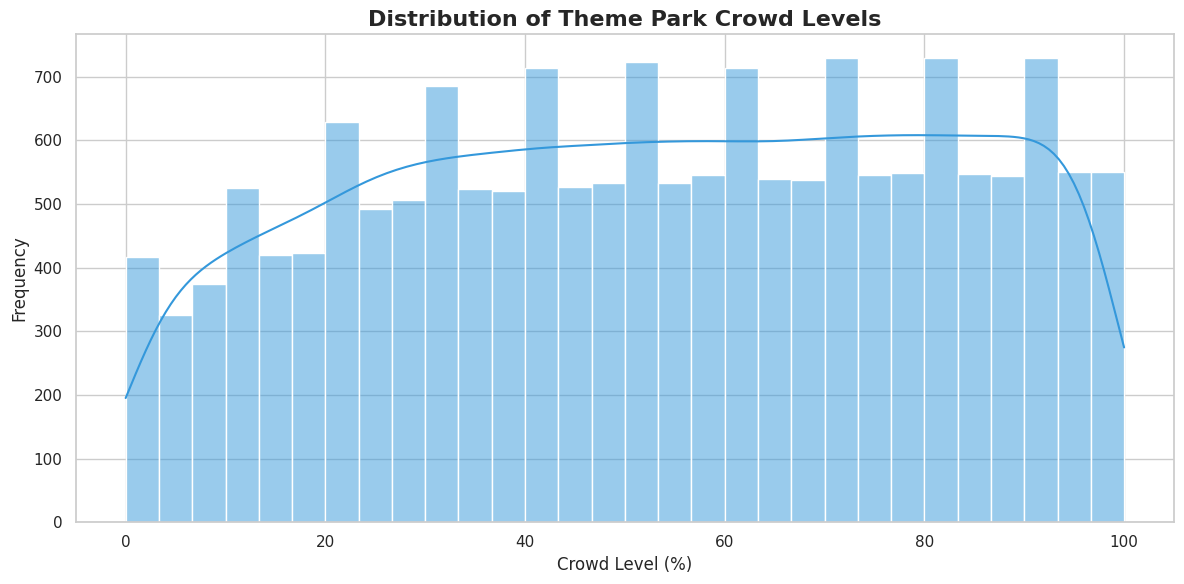

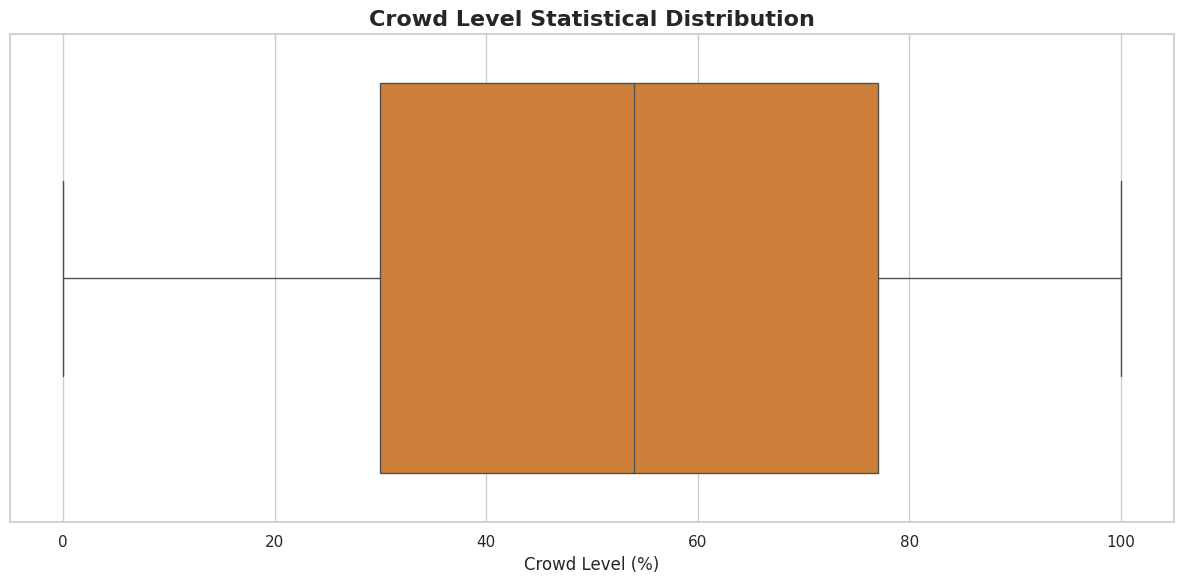

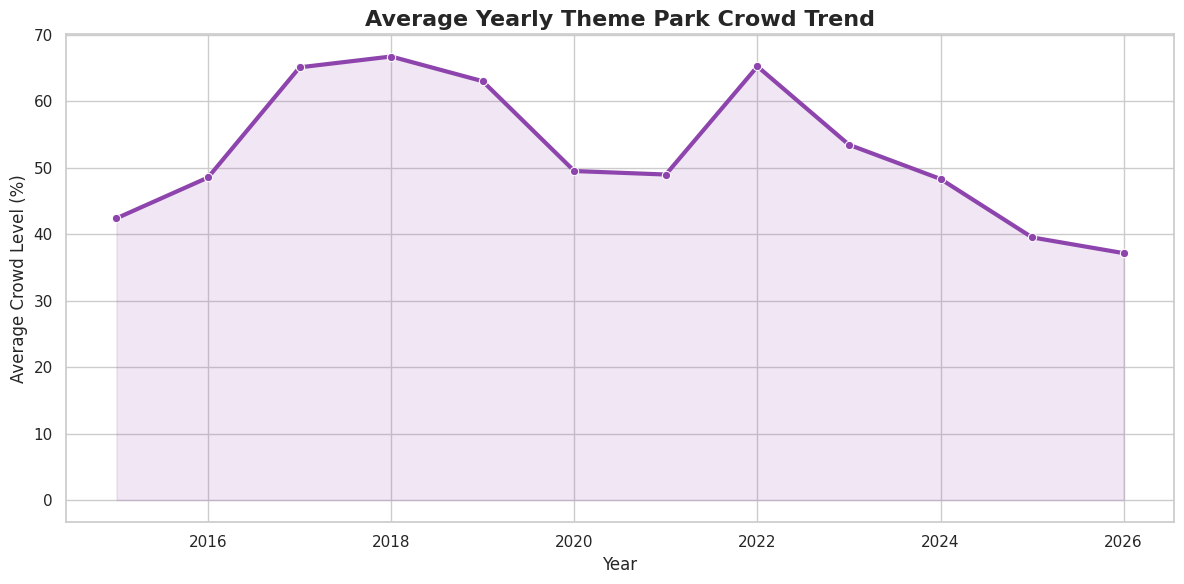

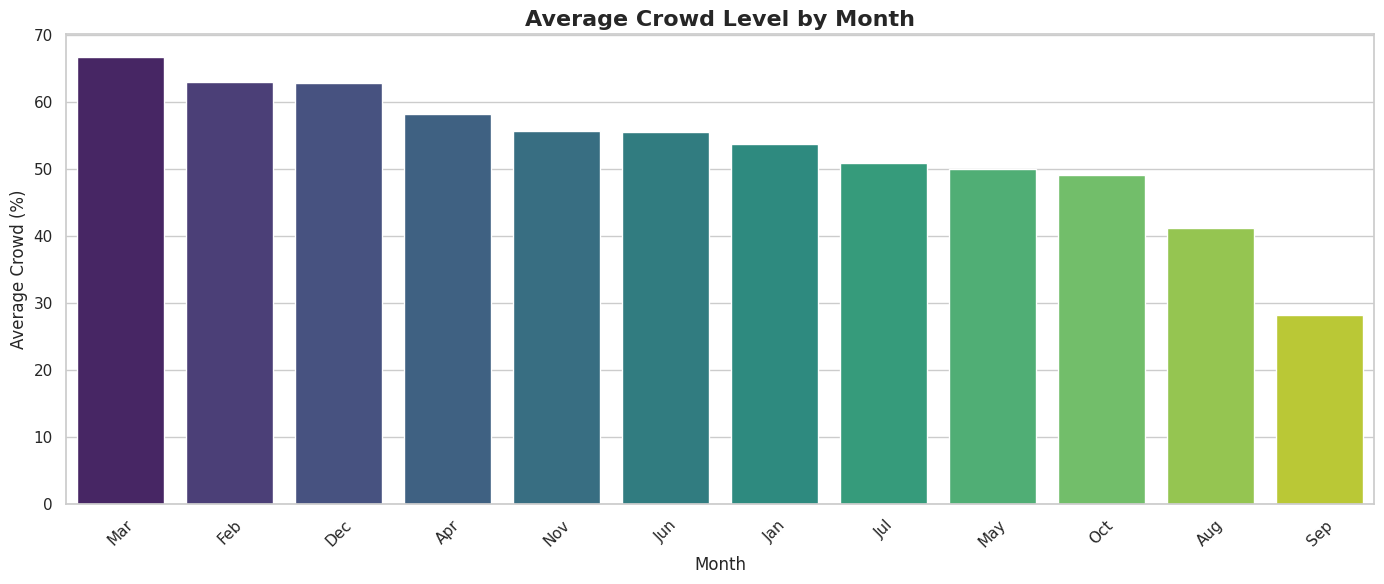

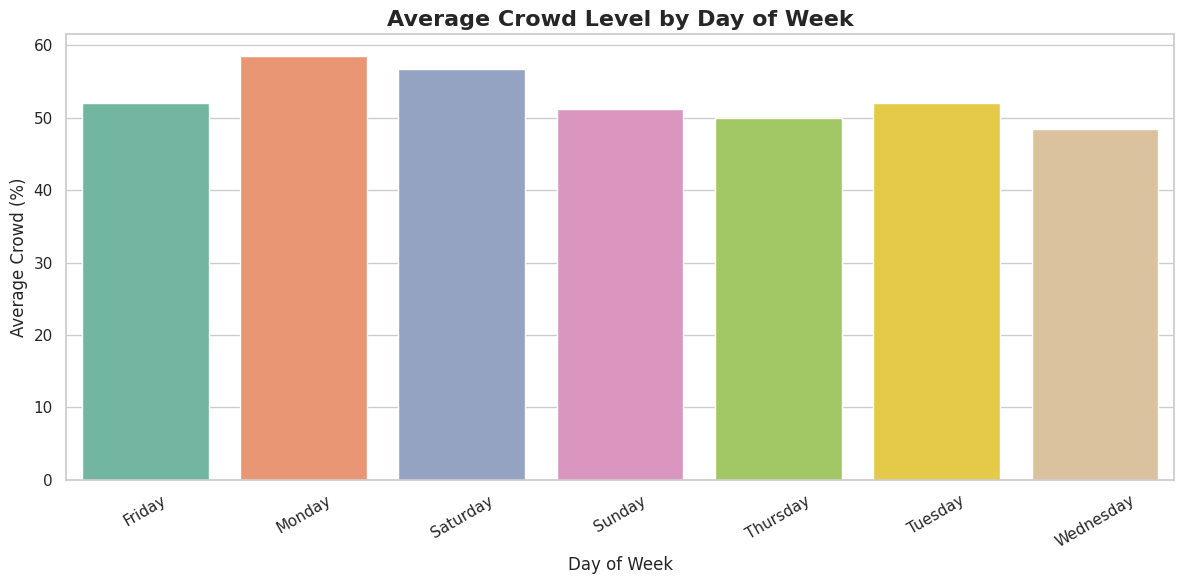

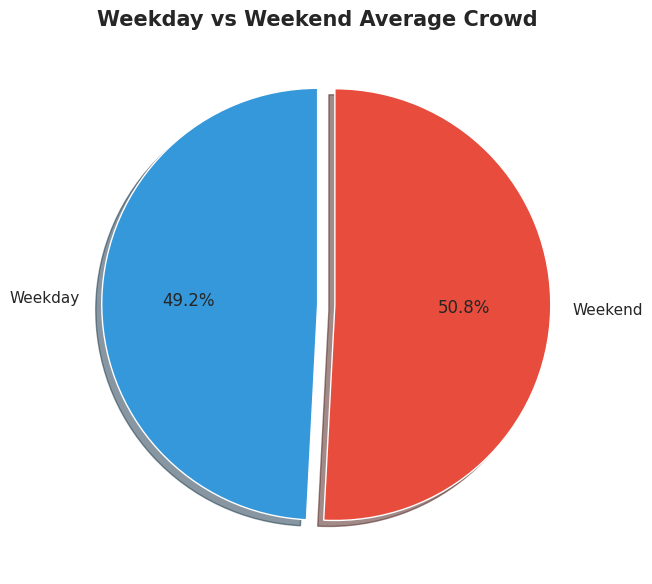

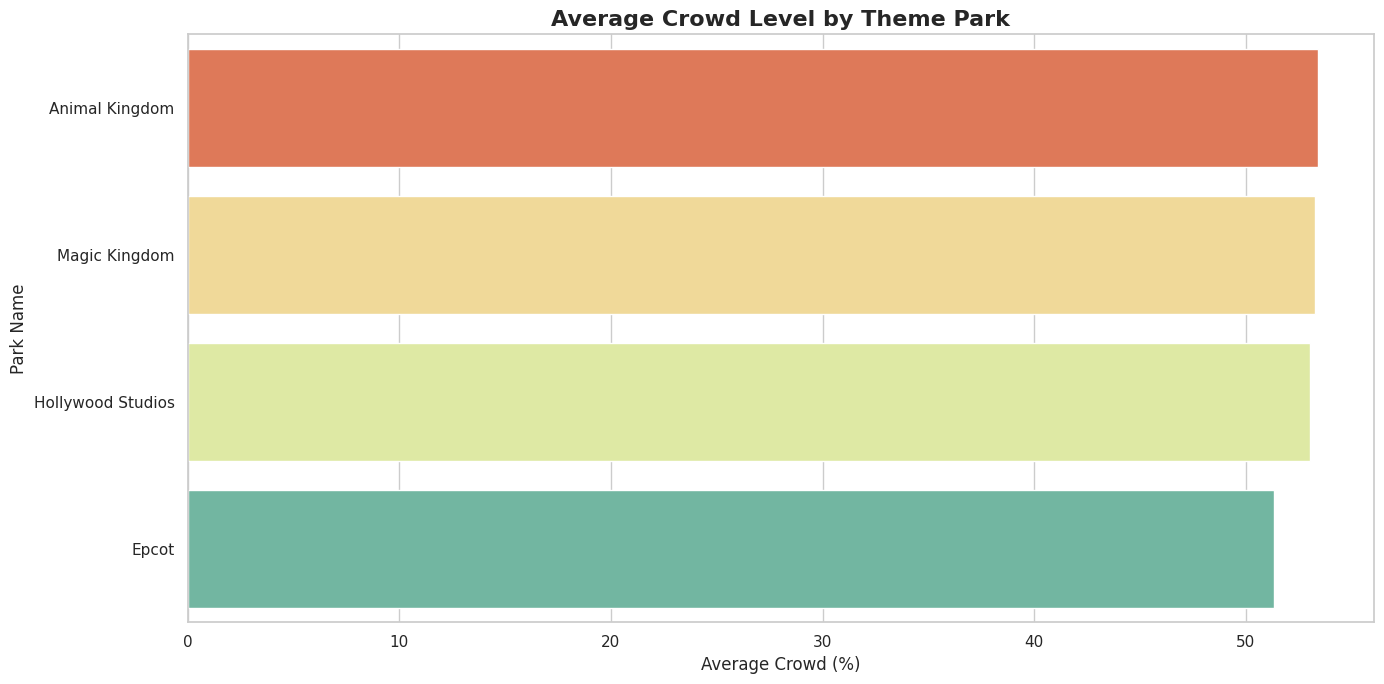

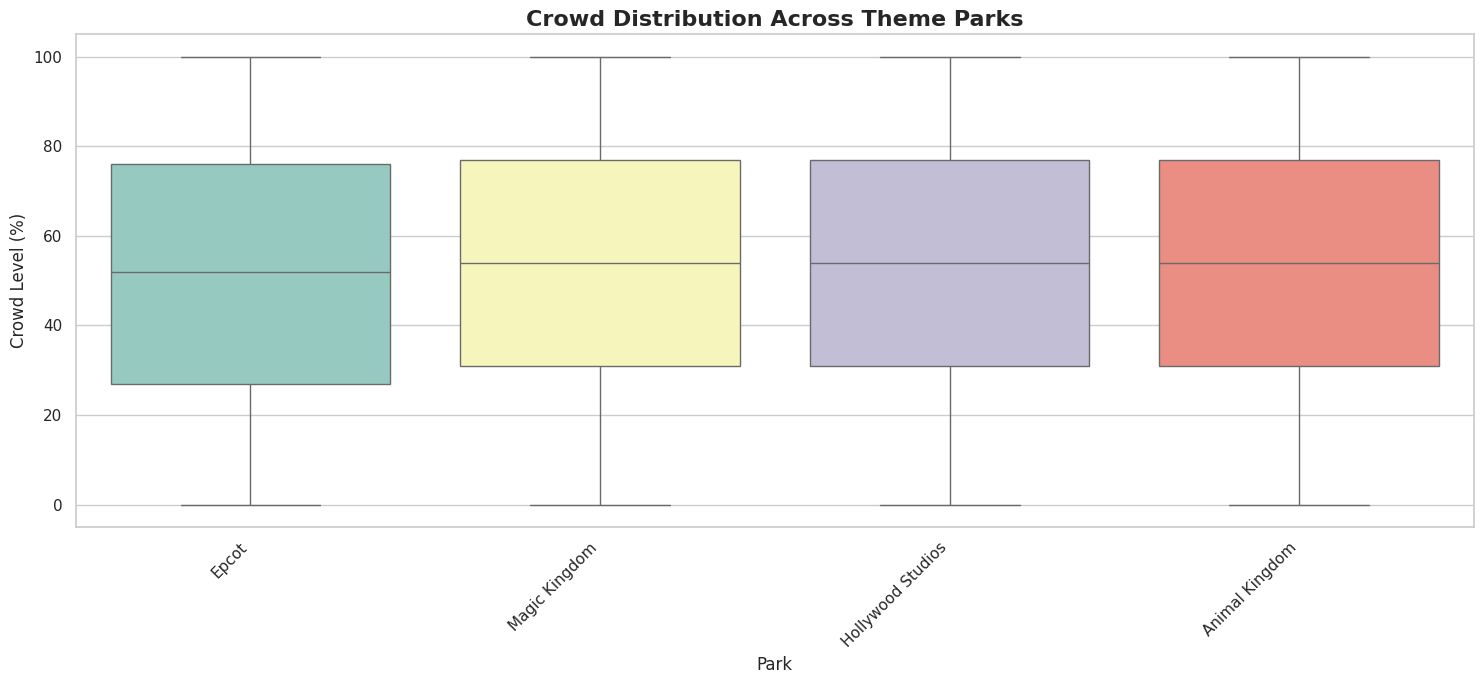

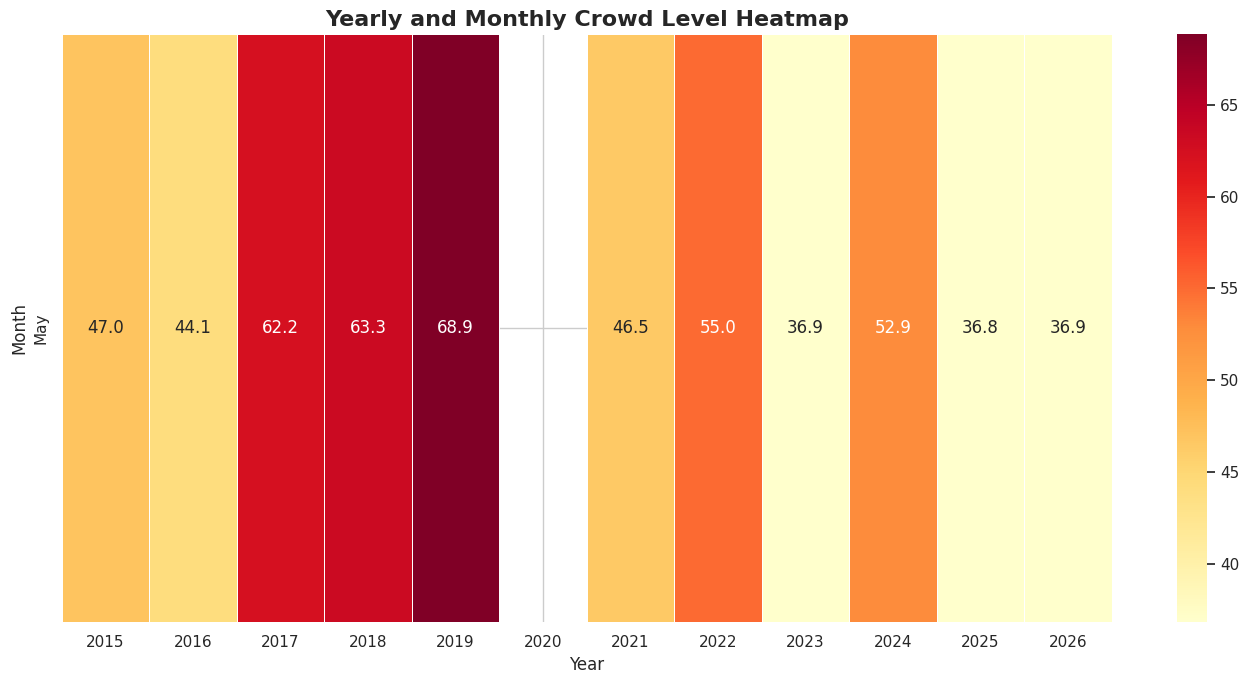

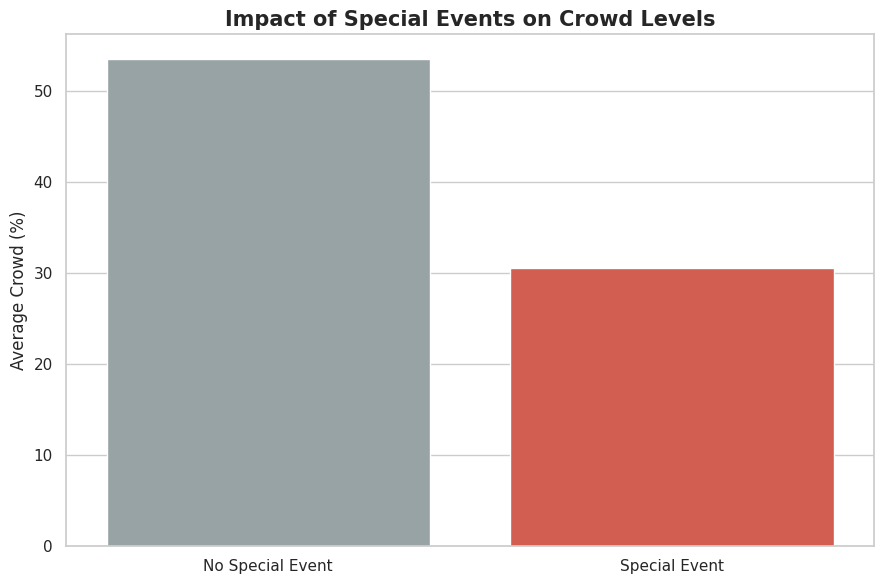

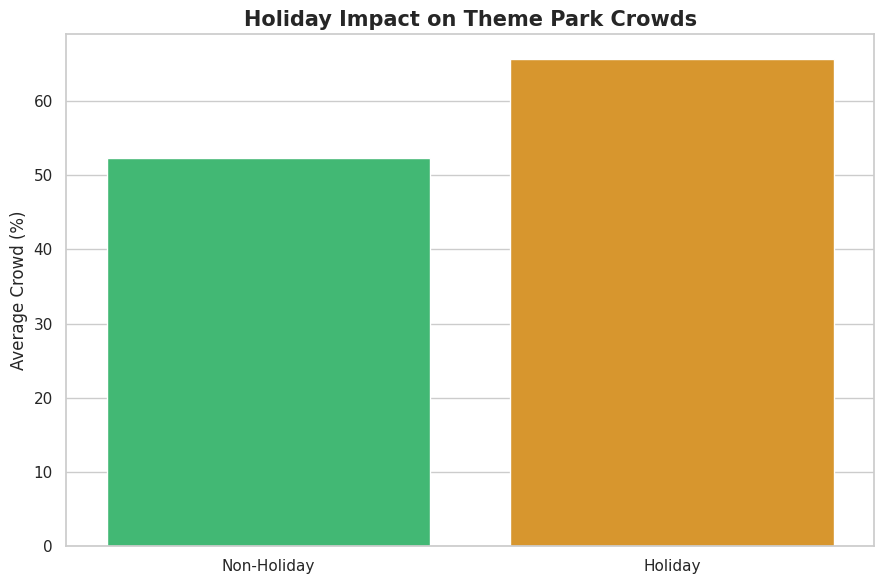

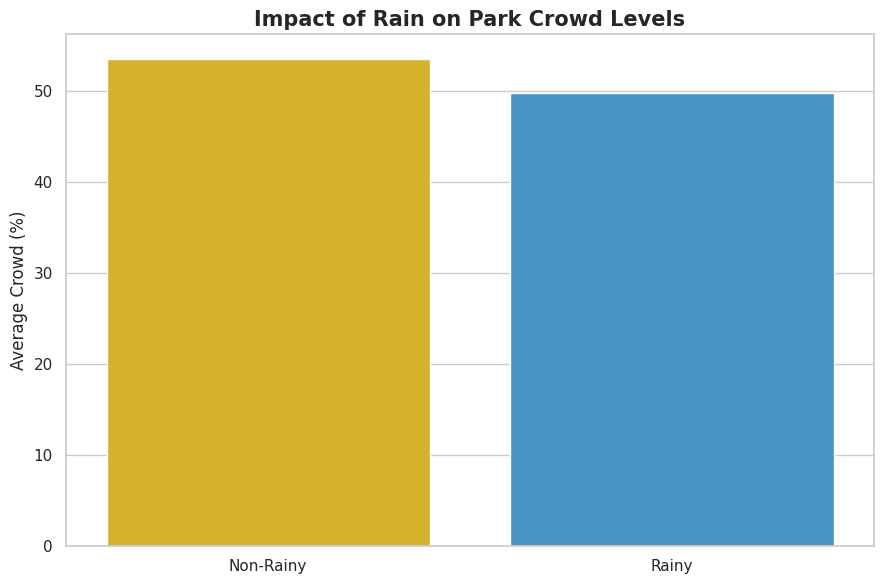

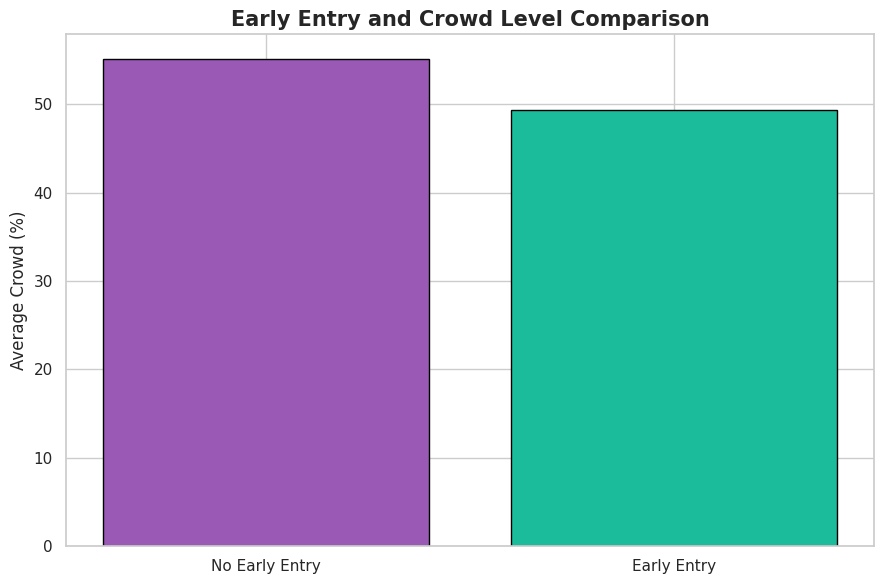

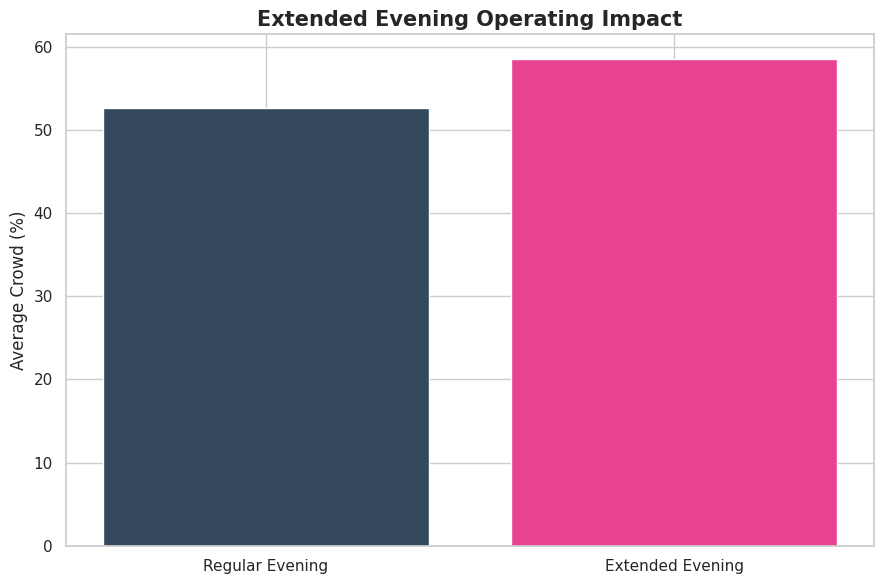

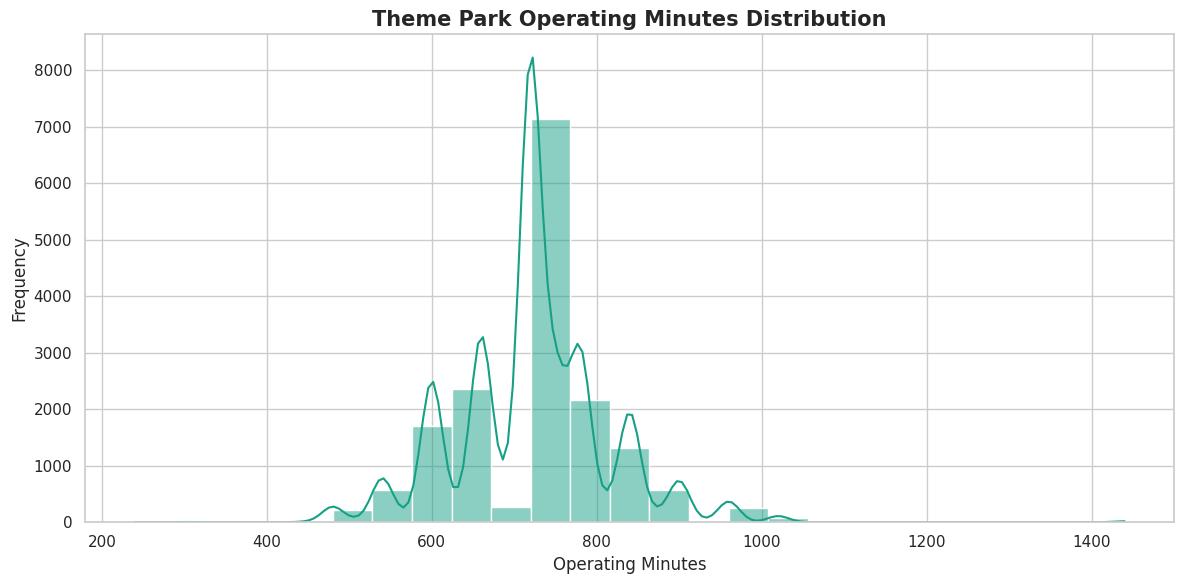

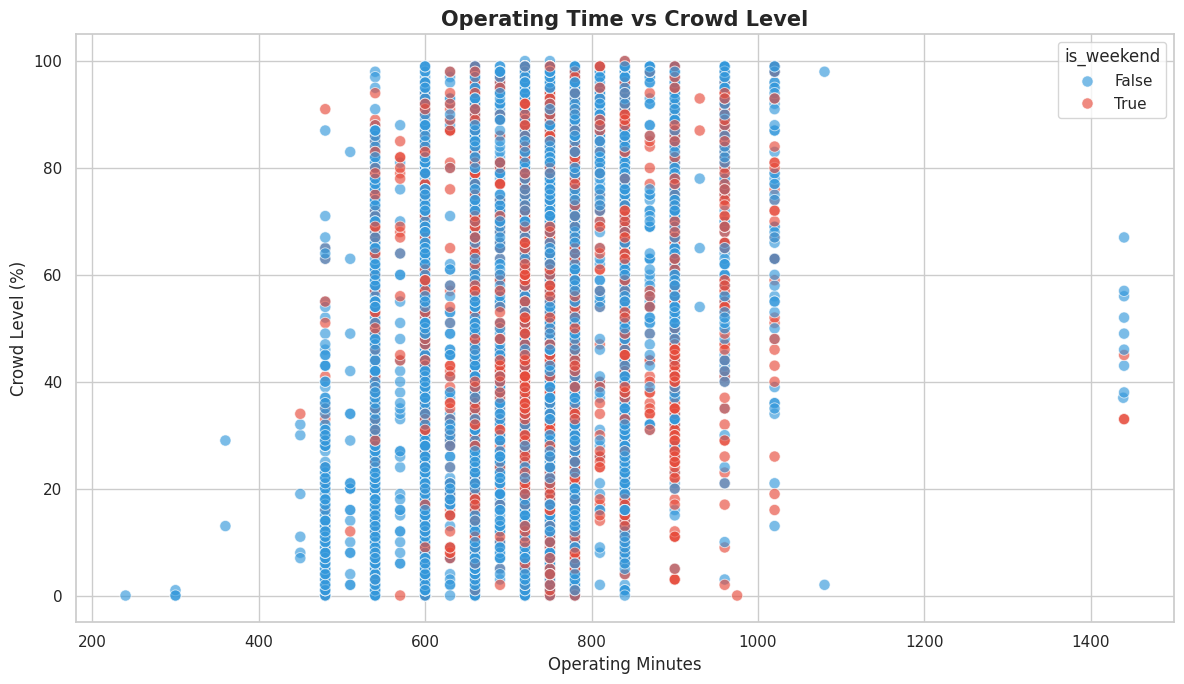

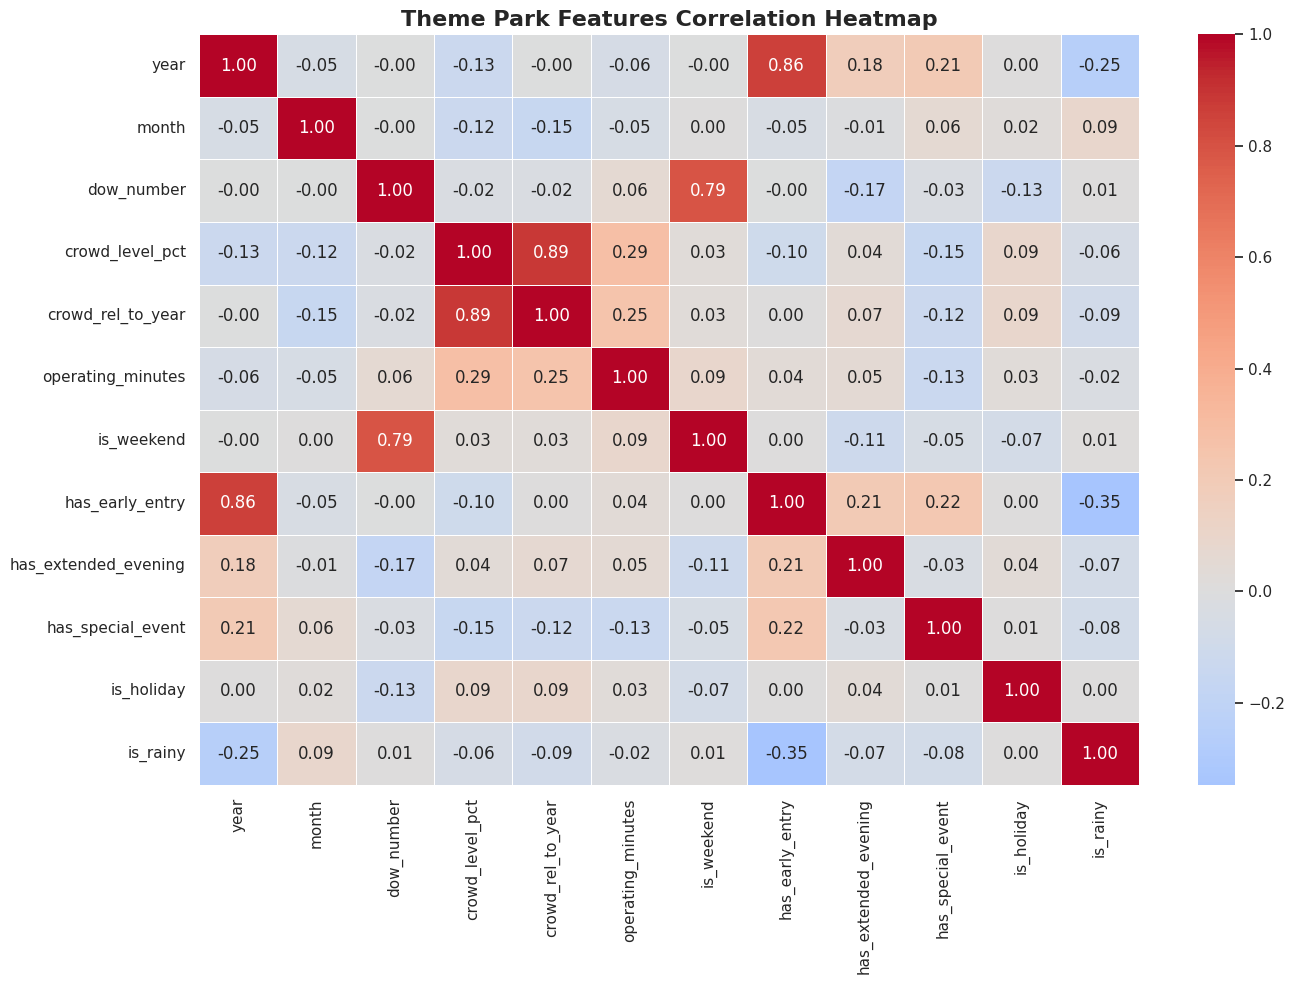

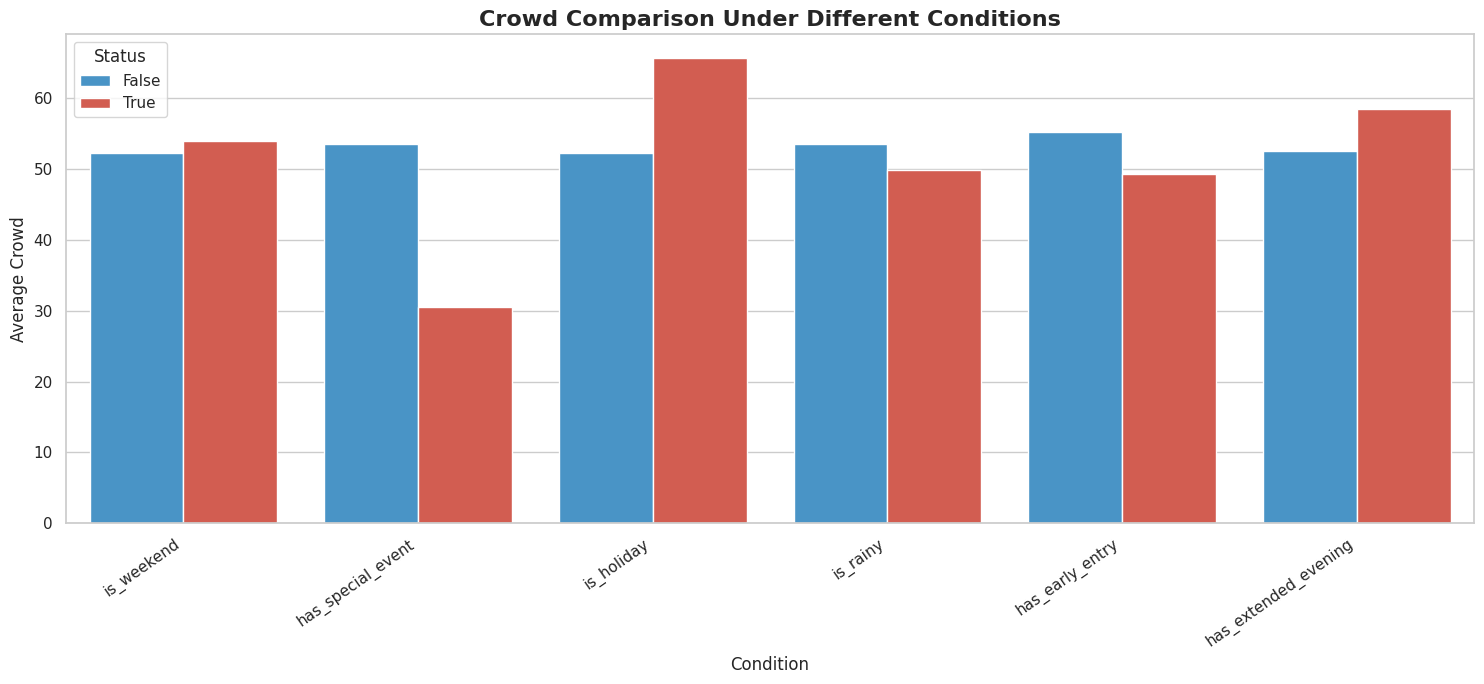

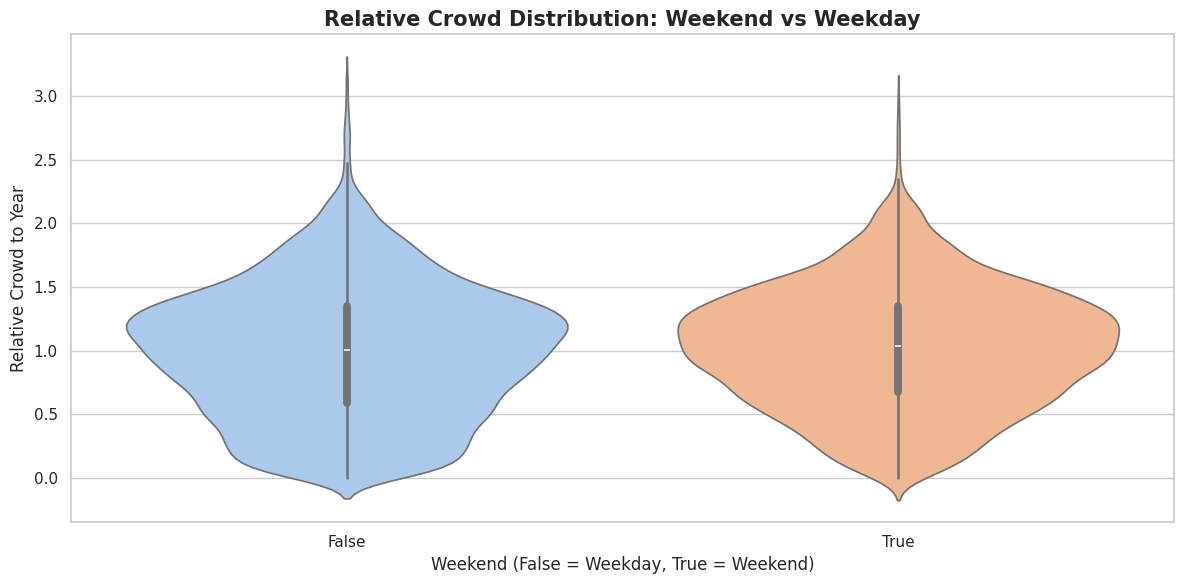

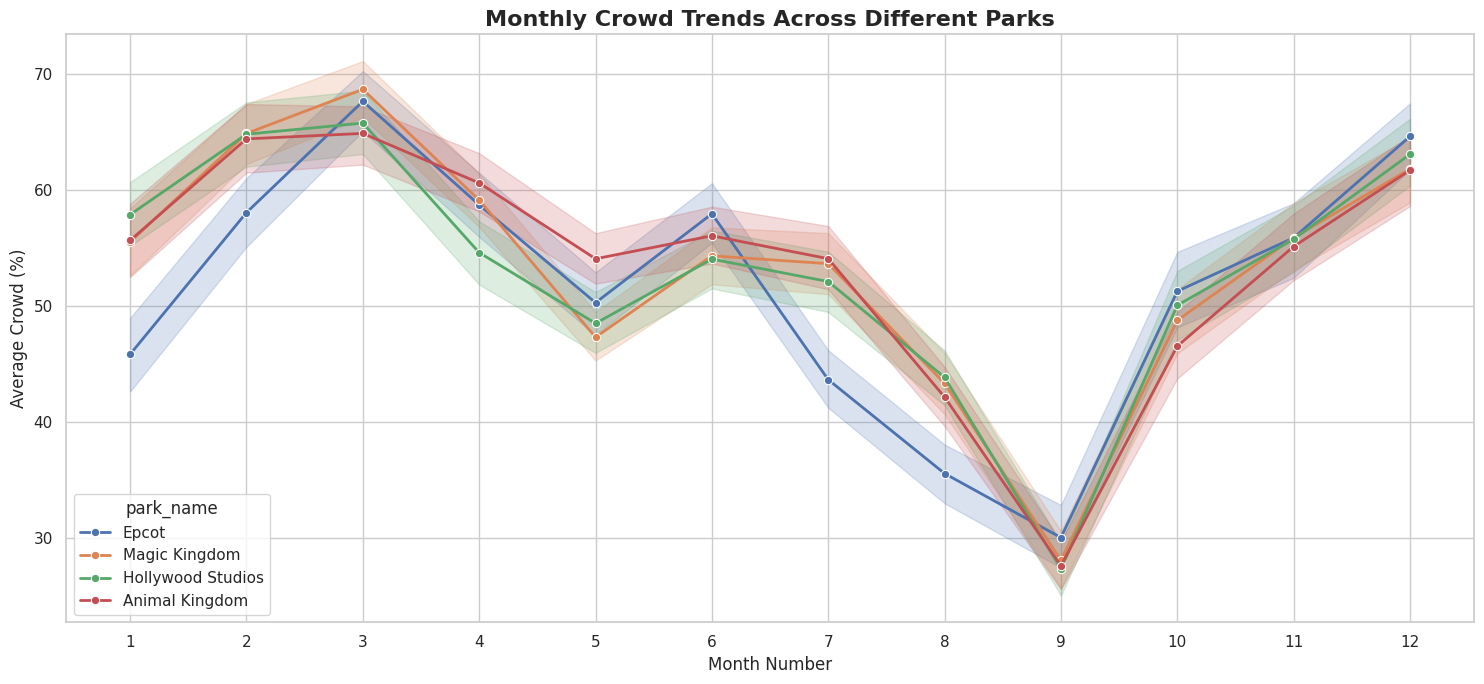

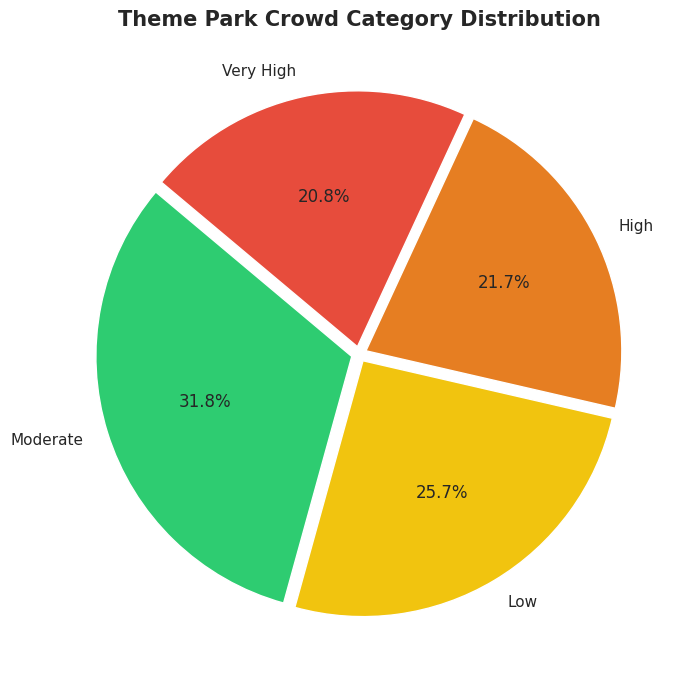


FINAL THEME PARK CROWD ANALYSIS INSIGHTS

1. Highest Average Crowd Park:
Animal Kingdom : 53.39 %

2. Lowest Average Crowd Park:
Epcot : 51.35 %

3. Busiest Month:
Mar : 66.75 %

4. Least Crowded Month:
Sep : 28.25 %

5. Busiest Day of Week:
Monday : 58.61 %

6. Weekend Average Crowd:
54.02 %

7. Weekday Average Crowd:
52.26 %

8. Average Operating Minutes:
721.35

9. Overall Average Crowd:
52.77 %

10. Special Event Crowd:
30.55 %

11. Holiday Crowd:
65.75 %

12. Rainy Day Crowd:
49.82 %

VISUALIZATION ANALYSIS COMPLETED SUCCESSFULLY!


In [14]:
import plotly.express as px
import plotly.graph_objects as go

from matplotlib.ticker import PercentFormatter

# ------------------------------------------------------------
# 1. DATA PREPROCESSING
# ------------------------------------------------------------

# Use existing dataframe: df
df = df.copy()

print("=" * 70)
print("THEME PARK CROWD ANALYSIS")
print("=" * 70)

print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

# Convert date column
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Convert numeric columns
numeric_cols = [
    'year', 'month', 'dow_number', 'crowd_level_pct',
    'crowd_rel_to_year', 'operating_minutes'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Convert boolean columns safely
bool_cols = [
    'is_weekend', 'has_early_entry',
    'has_extended_evening', 'has_special_event',
    'is_holiday', 'is_rainy'
]

for col in bool_cols:
    if df[col].dtype == 'object':
        df[col] = (
            df[col].astype(str).str.strip().str.lower()
            .map({
                'true': True, 'false': False,
                '1': True, '0': False,
                'yes': True, 'no': False
            })
        )

# Fill missing values for analysis
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

for col in bool_cols:
    df[col] = df[col].fillna(False).astype(bool)

df['park_name'] = df['park_name'].fillna('Unknown')
df['month_name'] = df['month_name'].fillna('Unknown')
df['day_of_week'] = df['day_of_week'].fillna('Unknown')
df['park_id'] = df['park_id'].fillna('Unknown')

df = df.dropna(subset=['date'])

# Limit crowd values to valid percentage range for percentage charts
df['crowd_level_pct'] = df['crowd_level_pct'].clip(0, 100)

sns.set_theme(style="whitegrid", context="notebook")

print("\nCleaned Dataset Shape:", df.shape)

# ------------------------------------------------------------
# 2. DATASET OVERVIEW
# ------------------------------------------------------------

print("\nSTATISTICAL SUMMARY")
display(df.describe(include='all').T)

print("\nUnique Parks:", df['park_name'].nunique())
print("Years Covered:", sorted(df['year'].unique()))
print("Total Records:", len(df))

# ------------------------------------------------------------
# 3. CROWD LEVEL DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))
sns.histplot(
    data=df,
    x='crowd_level_pct',
    bins=30,
    kde=True,
    color='#3498DB'
)
plt.title('Distribution of Theme Park Crowd Levels',
          fontsize=16, fontweight='bold')
plt.xlabel('Crowd Level (%)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. CROWD LEVEL BOX PLOT
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x='crowd_level_pct',
    color='#E67E22'
)
plt.title('Crowd Level Statistical Distribution',
          fontsize=16, fontweight='bold')
plt.xlabel('Crowd Level (%)')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. YEARLY CROWD TREND
# ------------------------------------------------------------

yearly = df.groupby('year', as_index=False)['crowd_level_pct'].mean()

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=yearly,
    x='year',
    y='crowd_level_pct',
    marker='o',
    linewidth=3,
    color='#8E44AD'
)
plt.fill_between(
    yearly['year'],
    yearly['crowd_level_pct'],
    alpha=0.15,
    color='#9B59B6'
)
plt.title('Average Yearly Theme Park Crowd Trend',
          fontsize=16, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Average Crowd Level (%)')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. MONTHLY CROWD ANALYSIS
# ------------------------------------------------------------

monthly = (
    df.groupby('month_name')['crowd_level_pct']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 6))
sns.barplot(
    x=monthly.index,
    y=monthly.values,
    hue=monthly.index,
    palette='viridis',
    legend=False
)
plt.title('Average Crowd Level by Month',
          fontsize=16, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Average Crowd (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. DAY OF WEEK ANALYSIS
# ------------------------------------------------------------

dow = df.groupby('day_of_week')['crowd_level_pct'].mean()

plt.figure(figsize=(12, 6))
sns.barplot(
    x=dow.index,
    y=dow.values,
    hue=dow.index,
    palette='Set2',
    legend=False
)
plt.title('Average Crowd Level by Day of Week',
          fontsize=16, fontweight='bold')
plt.xlabel('Day of Week')
plt.ylabel('Average Crowd (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. WEEKEND VS WEEKDAY
# ------------------------------------------------------------

weekend = df.groupby('is_weekend')['crowd_level_pct'].mean()

plt.figure(figsize=(8, 6))
plt.pie(
    weekend.values,
    labels=['Weekday', 'Weekend'],
    autopct='%1.1f%%',
    colors=['#3498DB', '#E74C3C'],
    startangle=90,
    explode=(0, 0.08),
    shadow=True
)
plt.title('Weekday vs Weekend Average Crowd',
          fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. PARK-WISE CROWD COMPARISON
# ------------------------------------------------------------

park_crowd = (
    df.groupby('park_name')['crowd_level_pct']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 7))
sns.barplot(
    x=park_crowd.values,
    y=park_crowd.index,
    hue=park_crowd.index,
    palette='Spectral',
    legend=False
)
plt.title('Average Crowd Level by Theme Park',
          fontsize=16, fontweight='bold')
plt.xlabel('Average Crowd (%)')
plt.ylabel('Park Name')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. PARK-WISE CROWD DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))
sns.boxplot(
    data=df,
    x='park_name',
    y='crowd_level_pct',
    hue='park_name',
    palette='Set3',
    legend=False
)
plt.title('Crowd Distribution Across Theme Parks',
          fontsize=16, fontweight='bold')
plt.xlabel('Park')
plt.ylabel('Crowd Level (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. MONTH VS YEAR HEATMAP
# ------------------------------------------------------------

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

pivot = df.pivot_table(
    index='month_name',
    columns='year',
    values='crowd_level_pct',
    aggfunc='mean'
)

pivot = pivot.reindex(
    [m for m in month_order if m in pivot.index]
)

plt.figure(figsize=(14, 7))
sns.heatmap(
    pivot,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5
)
plt.title('Yearly and Monthly Crowd Level Heatmap',
          fontsize=16, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Month')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. SPECIAL EVENT IMPACT
# ------------------------------------------------------------

event_data = df.groupby('has_special_event')['crowd_level_pct'].mean()

plt.figure(figsize=(9, 6))
sns.barplot(
    x=['No Special Event', 'Special Event'],
    y=event_data.reindex([False, True]).values,
    hue=['No Special Event', 'Special Event'],
    palette=['#95A5A6', '#E74C3C'],
    legend=False
)
plt.title('Impact of Special Events on Crowd Levels',
          fontsize=15, fontweight='bold')
plt.ylabel('Average Crowd (%)')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. HOLIDAY VS NON-HOLIDAY
# ------------------------------------------------------------

holiday_data = df.groupby('is_holiday')['crowd_level_pct'].mean()

plt.figure(figsize=(9, 6))
sns.barplot(
    x=['Non-Holiday', 'Holiday'],
    y=holiday_data.reindex([False, True]).values,
    hue=['Non-Holiday', 'Holiday'],
    palette=['#2ECC71', '#F39C12'],
    legend=False
)
plt.title('Holiday Impact on Theme Park Crowds',
          fontsize=15, fontweight='bold')
plt.ylabel('Average Crowd (%)')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 14. RAINY VS NON-RAINY DAYS
# ------------------------------------------------------------

rain_data = df.groupby('is_rainy')['crowd_level_pct'].mean()

plt.figure(figsize=(9, 6))
sns.barplot(
    x=['Non-Rainy', 'Rainy'],
    y=rain_data.reindex([False, True]).values,
    hue=['Non-Rainy', 'Rainy'],
    palette=['#F1C40F', '#3498DB'],
    legend=False
)
plt.title('Impact of Rain on Park Crowd Levels',
          fontsize=15, fontweight='bold')
plt.ylabel('Average Crowd (%)')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 15. EARLY ENTRY IMPACT
# ------------------------------------------------------------

early = df.groupby('has_early_entry')['crowd_level_pct'].mean()

plt.figure(figsize=(9, 6))
plt.bar(
    ['No Early Entry', 'Early Entry'],
    early.reindex([False, True]).values,
    color=['#9B59B6', '#1ABC9C'],
    edgecolor='black'
)
plt.title('Early Entry and Crowd Level Comparison',
          fontsize=15, fontweight='bold')
plt.ylabel('Average Crowd (%)')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 16. EXTENDED EVENING IMPACT
# ------------------------------------------------------------

evening = df.groupby('has_extended_evening')['crowd_level_pct'].mean()

plt.figure(figsize=(9, 6))
plt.bar(
    ['Regular Evening', 'Extended Evening'],
    evening.reindex([False, True]).values,
    color=['#34495E', '#E84393']
)
plt.title('Extended Evening Operating Impact',
          fontsize=15, fontweight='bold')
plt.ylabel('Average Crowd (%)')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 17. OPERATING MINUTES DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))
sns.histplot(
    data=df,
    x='operating_minutes',
    kde=True,
    color='#16A085',
    bins=25
)
plt.title('Theme Park Operating Minutes Distribution',
          fontsize=15, fontweight='bold')
plt.xlabel('Operating Minutes')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 18. OPERATING MINUTES VS CROWD LEVEL
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df,
    x='operating_minutes',
    y='crowd_level_pct',
    hue='is_weekend',
    palette={True: '#E74C3C', False: '#3498DB'},
    alpha=0.65,
    s=65
)
plt.title('Operating Time vs Crowd Level',
          fontsize=15, fontweight='bold')
plt.xlabel('Operating Minutes')
plt.ylabel('Crowd Level (%)')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 19. CORRELATION HEATMAP
# ------------------------------------------------------------

corr_cols = [
    'year', 'month', 'dow_number',
    'crowd_level_pct', 'crowd_rel_to_year',
    'operating_minutes', 'is_weekend',
    'has_early_entry', 'has_extended_evening',
    'has_special_event', 'is_holiday', 'is_rainy'
]

corr = df[corr_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)
plt.title('Theme Park Features Correlation Heatmap',
          fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 20. CROWD LEVEL VS SPECIAL CONDITIONS
# ------------------------------------------------------------

conditions = [
    'is_weekend',
    'has_special_event',
    'is_holiday',
    'is_rainy',
    'has_early_entry',
    'has_extended_evening'
]

condition_data = []

for col in conditions:
    for value in [False, True]:
        subset = df[df[col] == value]
        condition_data.append({
            'Condition': col,
            'Status': str(value),
            'Average Crowd': subset['crowd_level_pct'].mean()
        })

condition_df = pd.DataFrame(condition_data)

plt.figure(figsize=(15, 7))
sns.barplot(
    data=condition_df,
    x='Condition',
    y='Average Crowd',
    hue='Status',
    palette=['#3498DB', '#E74C3C']
)
plt.title('Crowd Comparison Under Different Conditions',
          fontsize=16, fontweight='bold')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 21. RELATIVE CROWD TO YEAR
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))
sns.violinplot(
    data=df,
    x='is_weekend',
    y='crowd_rel_to_year',
    hue='is_weekend',
    palette='pastel',
    legend=False
)
plt.title('Relative Crowd Distribution: Weekend vs Weekday',
          fontsize=15, fontweight='bold')
plt.xlabel('Weekend (False = Weekday, True = Weekend)')
plt.ylabel('Relative Crowd to Year')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 22. MONTHLY CROWD TREND BY PARK
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))
sns.lineplot(
    data=df,
    x='month',
    y='crowd_level_pct',
    hue='park_name',
    marker='o',
    linewidth=2
)
plt.title('Monthly Crowd Trends Across Different Parks',
          fontsize=16, fontweight='bold')
plt.xlabel('Month Number')
plt.ylabel('Average Crowd (%)')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 23. CROWD LEVEL PIE CHART
# ------------------------------------------------------------

df['crowd_category'] = pd.cut(
    df['crowd_level_pct'],
    bins=[-0.01, 30, 60, 80, 100],
    labels=['Low', 'Moderate', 'High', 'Very High']
)

crowd_counts = df['crowd_category'].value_counts()

plt.figure(figsize=(9, 7))
plt.pie(
    crowd_counts.values,
    labels=crowd_counts.index,
    autopct='%1.1f%%',
    colors=['#2ECC71', '#F1C40F', '#E67E22', '#E74C3C'],
    startangle=140,
    explode=[0.03] * len(crowd_counts)
)
plt.title('Theme Park Crowd Category Distribution',
          fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 24. INTERACTIVE PLOTLY CROWD TREND
# ------------------------------------------------------------

interactive = (
    df.groupby(['date', 'park_name'], as_index=False)
    ['crowd_level_pct'].mean()
)

fig = px.line(
    interactive,
    x='date',
    y='crowd_level_pct',
    color='park_name',
    markers=True,
    title='Interactive Theme Park Crowd Trends',
    template='plotly_white',
    color_discrete_sequence=px.colors.qualitative.Bold
)

fig.update_layout(
    xaxis_title='Date',
    yaxis_title='Crowd Level (%)',
    hovermode='x unified',
    title_x=0.5
)

fig.show()

# ------------------------------------------------------------
# 25. INTERACTIVE PARK CROWD COMPARISON
# ------------------------------------------------------------

park_interactive = (
    df.groupby('park_name', as_index=False)
    .agg(
        Average_Crowd=('crowd_level_pct', 'mean'),
        Average_Operating_Minutes=('operating_minutes', 'mean'),
        Records=('park_id', 'count')
    )
)

fig = px.bar(
    park_interactive.sort_values('Average_Crowd', ascending=False),
    x='park_name',
    y='Average_Crowd',
    color='Average_Crowd',
    hover_data=['Average_Operating_Minutes', 'Records'],
    color_continuous_scale='Turbo',
    title='Interactive Average Crowd by Theme Park',
    template='plotly_white'
)

fig.update_layout(title_x=0.5)
fig.show()

# ------------------------------------------------------------
# 26. FINAL DATA INSIGHTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL THEME PARK CROWD ANALYSIS INSIGHTS")
print("=" * 70)

print("\n1. Highest Average Crowd Park:")
print(park_crowd.idxmax(), ":", round(park_crowd.max(), 2), "%")

print("\n2. Lowest Average Crowd Park:")
print(park_crowd.idxmin(), ":", round(park_crowd.min(), 2), "%")

print("\n3. Busiest Month:")
print(monthly.idxmax(), ":", round(monthly.max(), 2), "%")

print("\n4. Least Crowded Month:")
print(monthly.idxmin(), ":", round(monthly.min(), 2), "%")

print("\n5. Busiest Day of Week:")
print(dow.idxmax(), ":", round(dow.max(), 2), "%")

print("\n6. Weekend Average Crowd:")
print(round(weekend.get(True, np.nan), 2), "%")

print("\n7. Weekday Average Crowd:")
print(round(weekend.get(False, np.nan), 2), "%")

print("\n8. Average Operating Minutes:")
print(round(df['operating_minutes'].mean(), 2))

print("\n9. Overall Average Crowd:")
print(round(df['crowd_level_pct'].mean(), 2), "%")

print("\n10. Special Event Crowd:")
print(round(event_data.get(True, np.nan), 2), "%")

print("\n11. Holiday Crowd:")
print(round(holiday_data.get(True, np.nan), 2), "%")

print("\n12. Rainy Day Crowd:")
print(round(rain_data.get(True, np.nan), 2), "%")

print("\n" + "=" * 70)
print("VISUALIZATION ANALYSIS COMPLETED SUCCESSFULLY!")
print("=" * 70)


## Feature engineering

THEME PARK CROWD PREDICTION - MACHINE LEARNING

Dataset Shape: (16682, 27)

Numerical Features: ['year', 'month', 'dow_number', 'operating_minutes', 'chained_index', 'attractions_this_year', 'mean_wait_all_tracked', 'qt_published_crowd_level', 'tracked_attractions', 'tracked_attractions_cov', 'day_of_year', 'week_of_year', 'high_crowd', 'day_of_month']

Categorical Features: ['park_name', 'month_name', 'day_of_week', 'is_weekend', 'has_early_entry', 'has_extended_evening', 'has_special_event', 'is_holiday', 'is_rainy']

Training Data: (13345, 23)
Testing Data: (3337, 23)

Encoded Target Classes:
0 = High
1 = Low
2 = Moderate
3 = Very High

Training: Logistic Regression
Accuracy : 61.7 %
Precision: 62.75 %
Recall   : 61.7 %
F1 Score : 61.19 %
ROC AUC  : 0.8665

Training: Decision Tree
Accuracy : 63.44 %
Precision: 64.33 %
Recall   : 63.44 %
F1 Score : 63.02 %
ROC AUC  : 0.8608

Training: Random Forest
Accuracy : 70.03 %
Precision: 70.69 %
Recall   : 70.03 %
F1 Score : 69.96 %
ROC AUC  :

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Hist Gradient Boosting,70.063,70.804,70.063,70.058,0.908
1,Random Forest,70.033,70.688,70.033,69.962,0.911
2,Extra Trees,67.366,68.013,67.366,67.163,0.898
3,SVM,65.808,66.892,65.808,65.407,0.889
4,KNN,64.879,65.521,64.879,64.828,0.875
5,Gradient Boosting,64.639,65.639,64.639,64.628,0.881
6,Decision Tree,63.440,64.330,63.440,63.017,0.861
7,Logistic Regression,61.702,62.753,61.702,61.191,0.866
8,Naive Bayes,52.922,51.784,52.922,43.295,0.844


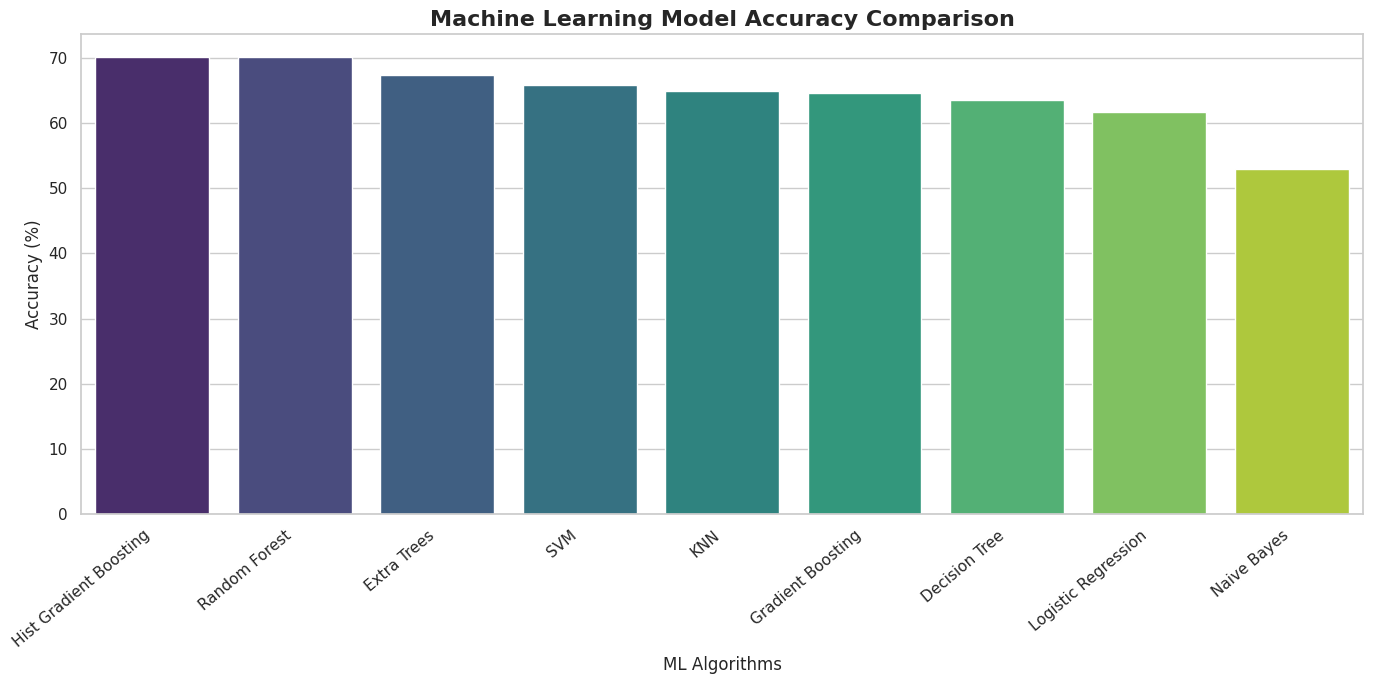

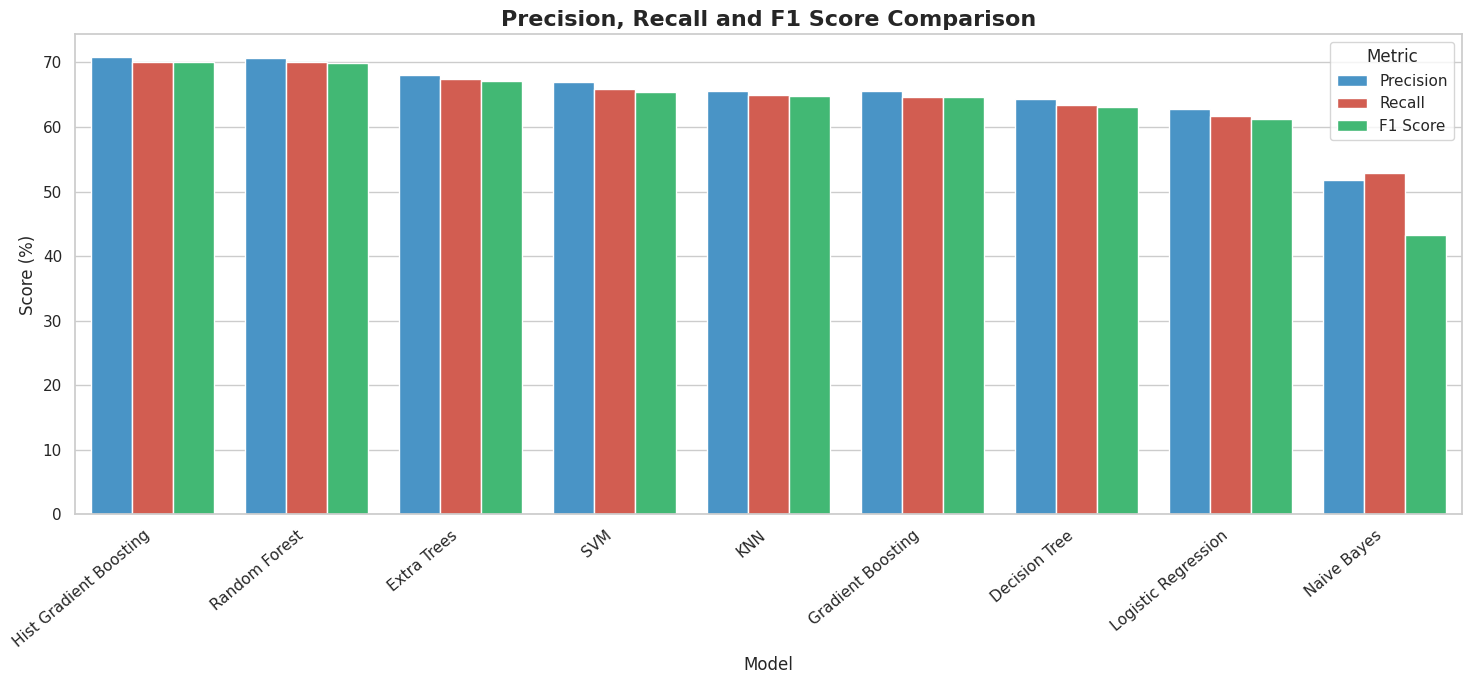

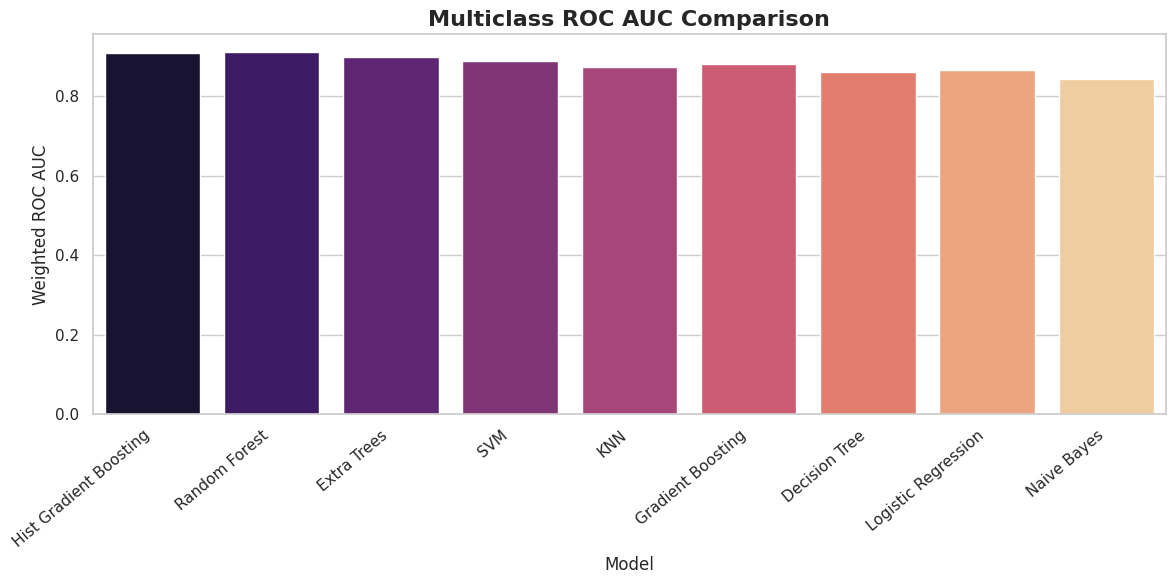


BEST MODEL: Hist Gradient Boosting

BEST MODEL CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.59      0.72      0.65       725
         Low       0.76      0.77      0.77       857
    Moderate       0.74      0.60      0.67      1062
   Very High       0.70      0.74      0.72       693

    accuracy                           0.70      3337
   macro avg       0.70      0.71      0.70      3337
weighted avg       0.71      0.70      0.70      3337



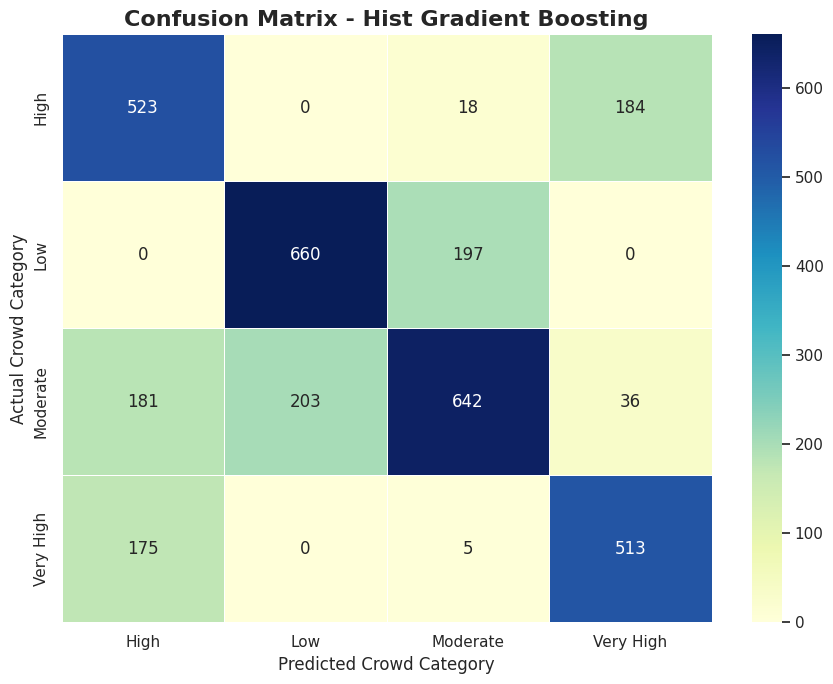

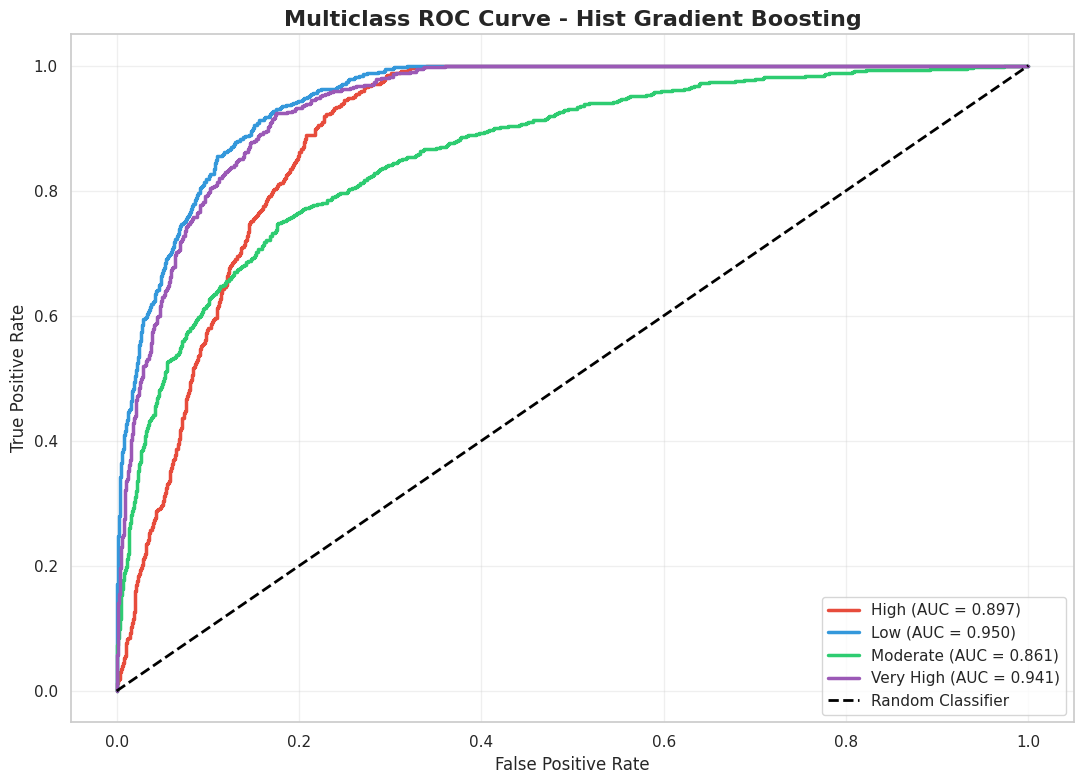

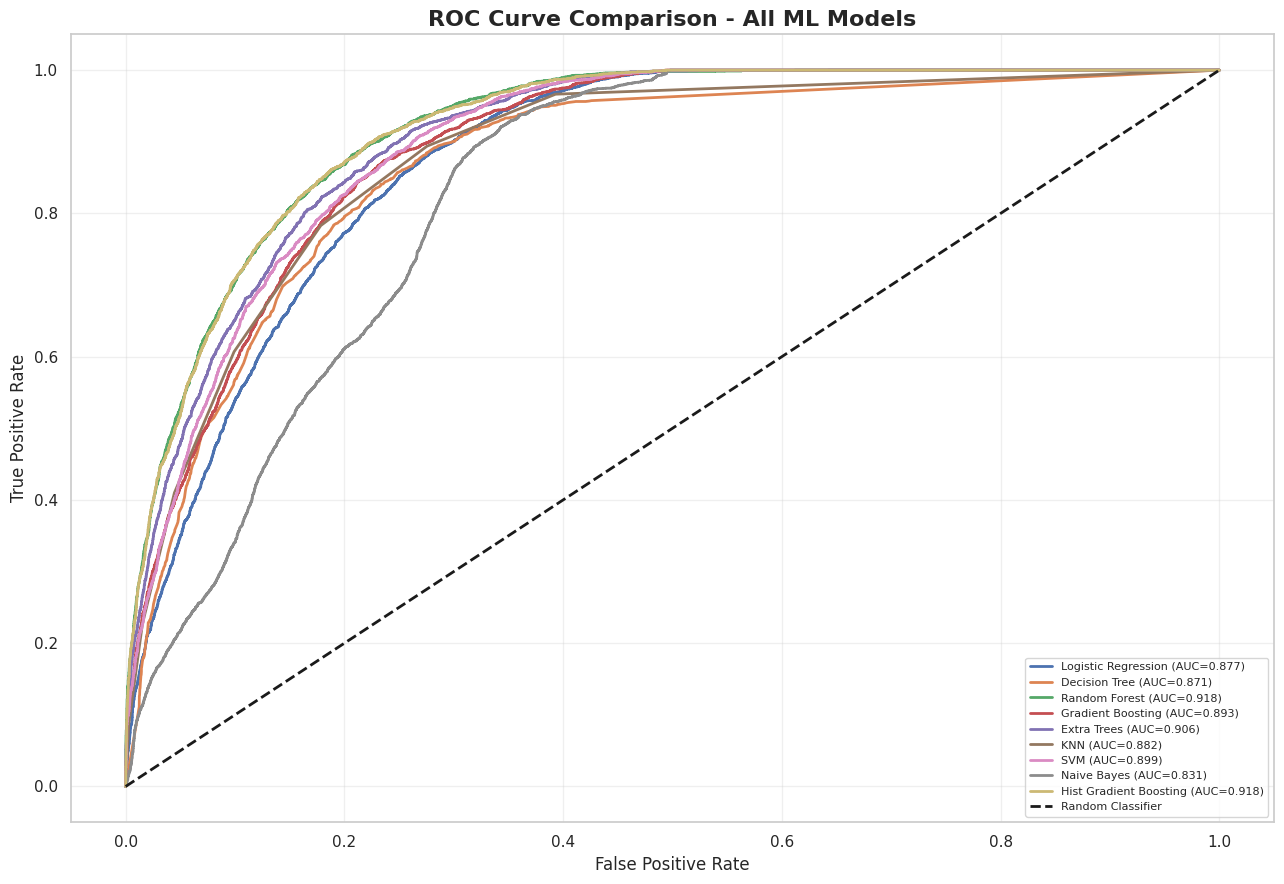


Selected model does not provide native feature importance.

ACTUAL VS PREDICTED SAMPLE


,Actual,Predicted
0,Moderate,Moderate
1,Low,Moderate
2,Moderate,Low
3,High,High
4,Moderate,Low
5,High,High
6,Low,Low
7,Moderate,Moderate
8,Very High,Very High
9,Moderate,Moderate



FINAL MACHINE LEARNING RESULTS
Total Dataset Records: 16682
Training Records: 13345
Testing Records: 3337
Number of Features: 23
Number of Classes: 4

Best Performing Model: Hist Gradient Boosting
Best Accuracy: 70.06 %
Best Weighted F1: 70.06 %
Best Weighted ROC AUC: 0.9083

Machine Learning Pipeline Completed Successfully!


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# ================================================================
# 1. LOAD AND PREPROCESS DATA
# ================================================================

data = df.copy()

print("=" * 70)
print("THEME PARK CROWD PREDICTION - MACHINE LEARNING")
print("=" * 70)

print("\nDataset Shape:", data.shape)

# Convert date column
data['date'] = pd.to_datetime(data['date'], errors='coerce')

# Extract useful date features
data['day_of_month'] = data['date'].dt.day
data['day_of_year'] = data['date'].dt.dayofyear

# Convert target into categories
data['crowd_level_pct'] = pd.to_numeric(
    data['crowd_level_pct'], errors='coerce'
)

data = data.dropna(subset=['crowd_level_pct'])

data['crowd_category'] = pd.cut(
    data['crowd_level_pct'],
    bins=[-np.inf, 30, 60, 80, np.inf],
    labels=['Low', 'Moderate', 'High', 'Very High'],
    right=True
)

data = data.dropna(subset=['crowd_category'])

# ================================================================
# 2. SELECT FEATURES AND TARGET
# ================================================================

target = 'crowd_category'

# Exclude crowd_level_pct to prevent target leakage
# Also exclude crowd_rel_to_year because it is derived from crowd level.
drop_columns = [
    'crowd_level_pct',
    'crowd_rel_to_year',
    'crowd_category',
    'date',
    'park_id'
]

X = data.drop(
    columns=drop_columns,
    errors='ignore'
)

y = data[target].astype(str)

# Remove constant columns
X = X.loc[:, X.nunique(dropna=False) > 1]

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNumerical Features:", numerical_cols)
print("\nCategorical Features:", categorical_cols)

# ================================================================
# 3. TRAIN TEST SPLIT
# ================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# ================================================================
# 4. LABEL ENCODING TARGET
# ================================================================

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

class_names = label_encoder.classes_
n_classes = len(class_names)

print("\nEncoded Target Classes:")
for i, name in enumerate(class_names):
    print(i, "=", name)

# ================================================================
# 5. FEATURE PREPROCESSING
# ================================================================

# OneHotEncoder for categorical features
# StandardScaler for numerical features
# Imputation for missing values

from sklearn.preprocessing import OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# ================================================================
# 6. DEFINE MACHINE LEARNING ALGORITHMS
# ================================================================

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=7
    ),

    'SVM': SVC(
        probability=True,
        class_weight='balanced',
        random_state=42
    ),

    'Naive Bayes': GaussianNB(),

    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.05,
        random_state=42
    )
}

# ================================================================
# 7. TRAIN MODELS AND EVALUATE PERFORMANCE
# ================================================================

results = []
trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", name)
    print("=" * 60)

    try:

        pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', model)
        ])

        pipeline.fit(X_train, y_train_encoded)

        y_pred = pipeline.predict(X_test)

        y_prob = pipeline.predict_proba(X_test)

        accuracy = accuracy_score(
            y_test_encoded, y_pred
        )

        precision = precision_score(
            y_test_encoded,
            y_pred,
            average='weighted',
            zero_division=0
        )

        recall = recall_score(
            y_test_encoded,
            y_pred,
            average='weighted',
            zero_division=0
        )

        f1 = f1_score(
            y_test_encoded,
            y_pred,
            average='weighted',
            zero_division=0
        )

        auc_score = roc_auc_score(
            y_test_encoded,
            y_prob,
            multi_class='ovr',
            average='weighted'
        )

        results.append({
            'Model': name,
            'Accuracy': accuracy * 100,
            'Precision': precision * 100,
            'Recall': recall * 100,
            'F1 Score': f1 * 100,
            'ROC AUC': auc_score
        })

        trained_models[name] = pipeline
        predictions[name] = y_pred
        probabilities[name] = y_prob

        print("Accuracy :", round(accuracy * 100, 2), "%")
        print("Precision:", round(precision * 100, 2), "%")
        print("Recall   :", round(recall * 100, 2), "%")
        print("F1 Score :", round(f1 * 100, 2), "%")
        print("ROC AUC  :", round(auc_score, 4))

    except Exception as e:
        print("Model Failed:", str(e))

# ================================================================
# 8. MODEL COMPARISON
# ================================================================

results_df = pd.DataFrame(results)

if results_df.empty:
    raise ValueError("All models failed. Check your dataset and target.")

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(3))

# ================================================================
# 9. MODEL ACCURACY COMPARISON
# ================================================================

plt.figure(figsize=(14, 7))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title(
    'Machine Learning Model Accuracy Comparison',
    fontsize=16,
    fontweight='bold'
)

plt.ylabel('Accuracy (%)')
plt.xlabel('ML Algorithms')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

# ================================================================
# 10. PRECISION, RECALL AND F1 COMPARISON
# ================================================================

metric_data = results_df.melt(
    id_vars='Model',
    value_vars=['Precision', 'Recall', 'F1 Score'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(15, 7))

sns.barplot(
    data=metric_data,
    x='Model',
    y='Score',
    hue='Metric',
    palette=['#3498DB', '#E74C3C', '#2ECC71']
)

plt.title(
    'Precision, Recall and F1 Score Comparison',
    fontsize=16,
    fontweight='bold'
)

plt.ylabel('Score (%)')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

# ================================================================
# 11. ROC AUC COMPARISON
# ================================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='ROC AUC',
    hue='Model',
    palette='magma',
    legend=False
)

plt.title('Multiclass ROC AUC Comparison',
          fontsize=16, fontweight='bold')

plt.ylabel('Weighted ROC AUC')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

# ================================================================
# 12. SELECT BEST MODEL
# ================================================================

best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

best_predictions = predictions[best_model_name]

best_probabilities = probabilities[best_model_name]

print("\nBEST MODEL:", best_model_name)

print("\nBEST MODEL CLASSIFICATION REPORT")

print(
    classification_report(
        y_test_encoded,
        best_predictions,
        labels=np.arange(n_classes),
        target_names=class_names,
        zero_division=0
    )
)

# ================================================================
# 13. CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(
    y_test_encoded,
    best_predictions,
    labels=np.arange(n_classes)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5
)

plt.title(
    f'Confusion Matrix - {best_model_name}',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Predicted Crowd Category')
plt.ylabel('Actual Crowd Category')
plt.tight_layout()
plt.show()

# ================================================================
# 14. MULTICLASS ROC CURVE - BEST MODEL
# ================================================================

y_test_binary = label_binarize(
    y_test_encoded,
    classes=np.arange(n_classes)
)

plt.figure(figsize=(11, 8))

colors = [
    '#E74C3C',
    '#3498DB',
    '#2ECC71',
    '#9B59B6',
    '#F39C12'
]

for i in range(n_classes):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        best_probabilities[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        color=colors[i % len(colors)],
        linewidth=2.5,
        label=f'{class_names[i]} (AUC = {roc_auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    linewidth=2,
    label='Random Classifier'
)

plt.title(
    f'Multiclass ROC Curve - {best_model_name}',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ================================================================
# 15. ROC CURVES FOR ALL MODELS
# ================================================================

plt.figure(figsize=(13, 9))

for name, y_prob in probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test_binary.ravel(),
        y_prob.ravel()
    )

    model_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{name} (AUC={model_auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    linewidth=2,
    label='Random Classifier'
)

plt.title(
    'ROC Curve Comparison - All ML Models',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right', fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ================================================================
# 16. FEATURE IMPORTANCE - TREE BASED BEST MODEL
# ================================================================

best_classifier = best_model.named_steps['classifier']

if hasattr(best_classifier, 'feature_importances_'):

    feature_names = (
        best_model.named_steps['preprocessor']
        .get_feature_names_out()
    )

    importance = best_classifier.feature_importances_

    feature_importance = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importance
    }).sort_values(
        by='Importance',
        ascending=False
    ).head(20)

    plt.figure(figsize=(12, 8))

    sns.barplot(
        data=feature_importance,
        x='Importance',
        y='Feature',
        hue='Feature',
        palette='coolwarm',
        legend=False
    )

    plt.title(
        f'Top 20 Feature Importance - {best_model_name}',
        fontsize=16,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()

    display(feature_importance)

else:
    print("\nSelected model does not provide native feature importance.")

# ================================================================
# 17. ACTUAL VS PREDICTED COMPARISON
# ================================================================

comparison = pd.DataFrame({
    'Actual': label_encoder.inverse_transform(y_test_encoded),
    'Predicted': label_encoder.inverse_transform(best_predictions)
})

print("\nACTUAL VS PREDICTED SAMPLE")
display(comparison.head(20))

# ================================================================
# 18. FINAL RESULTS
# ================================================================

print("\n" + "=" * 70)
print("FINAL MACHINE LEARNING RESULTS")
print("=" * 70)

print("Total Dataset Records:", len(data))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Number of Features:", X.shape[1])
print("Number of Classes:", n_classes)

print("\nBest Performing Model:", best_model_name)

print(
    "Best Accuracy:",
    round(results_df.iloc[0]['Accuracy'], 2), "%"
)

print(
    "Best Weighted F1:",
    round(results_df.iloc[0]['F1 Score'], 2), "%"
)

print(
    "Best Weighted ROC AUC:",
    round(results_df.iloc[0]['ROC AUC'], 4)
)

print("\nMachine Learning Pipeline Completed Successfully!")


## Thank you..pls upvote!!!!!!!!!